# Crowd-Filtered Residual Momentum

**Dennis Petushkov, Mitch Cahill, Krittrin Olarnrak — Data Driven Investing with AI and Python, Fall 2026**

**The question.** Among momentum winners, do *crowded* winners (the ones attention-chasing buyers pile into)
do worse than *quiet* winners? And is that specific to winners, or are crowded stocks just bad everywhere?

**Fixed before looking at results:**
- Strategy = our Assignment 2 residual momentum: NYSE breakpoints, value-weighted, top decile minus bottom decile, signal lagged one month.
- **Winners** = top decile (≥ NYSE 90th pct). **Middle stocks** (the comparison group) = between the NYSE 30th and 70th pct.
- **Crowd score** = average percentile rank of the five clues from our last presentation, all measured in the month *before* we trade.
- Within each group, split stocks into thirds by crowd score: quiet / middle / crowded.
- The filter drops the **30% most crowded winners**. Trading cost: **25 bps** per trade.

## Setup

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = [10, 4]
import warnings; warnings.filterwarnings('ignore')

BASE  = "https://raw.githubusercontent.com/amoreira2/UG54/refs/heads/main/assets/data"
panel = pd.read_parquet(f"{BASE}/panel_backbone_1980_2000.parquet")
FF    = pd.read_csv(f"{BASE}/ff_monthly.csv", index_col=0, parse_dates=True)
FF.index = FF.index + pd.offsets.MonthEnd(0)
SIX   = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'UMD']

SIGNALS = ['ResidualMomentum', 'MaxRet', 'RealizedVol', 'DolVol', 'Illiquidity', 'STreversal']
d = panel.copy()
for s in SIGNALS:
    d = d.merge(pd.read_parquet(f"{BASE}/signals/{s}.parquet"), on=['permno', 'date'], how='left')
d = d.sort_values(['permno', 'date'])
print(f"{len(d):,} stock-months loaded")

1,517,174 stock-months loaded


## Step 1 — The five crowd clues

The signal menu stores every signal so that *higher = expected to earn more*, so MaxRet and RealizedVol come in as
negative numbers. We flip them so that **higher = more crowded**. We checked each one against the raw data
(e.g. `STreversal` is exactly minus this month's return).

| Clue | What it is | From |
|---|---|---|
| `MAX` | biggest single-day return this month | −MaxRet |
| `VOL` | volatility of daily returns this month | −RealizedVol |
| `TURN` | trading volume, relative to company size | −DolVol − log(size) |
| `ILLIQ` | illiquidity (price moves per dollar traded) | Illiquidity |
| `RET1M` | this month's return | −STreversal |

**Why `TURN` and not raw dollar volume:** raw dollar volume is ~86% just company size, so "lots of volume" would
mostly mean "big company." Dividing by size makes it a turnover-style measure.

In [2]:
CROWD = ['MAX', 'VOL', 'TURN', 'ILLIQ', 'RET1M']
d['MAX']   = -d['MaxRet']
d['VOL']   = -d['RealizedVol']
d['TURN']  = -d['DolVol'] - np.log(d['me'].where(d['me'] > 0))
d['ILLIQ'] =  d['Illiquidity']
d['RET1M'] = -d['STreversal']

# Lag everything one month: we sort on what we knew last month and earn this month's ret
g = d.groupby('permno')
d['me_l1']  = g['me'].shift(1)
d['sig_l1'] = g['ResidualMomentum'].shift(1)
for c in CROWD:
    d[c + '_l1'] = g[c].shift(1)
d = d.dropna(subset=['ret', 'me_l1', 'sig_l1'])
d = d[d.me_l1 > 0]

# Crowd score: average of the five percentile ranks (within each month, across all stocks)
for c in CROWD:
    d[c] = d.groupby('date')[c + '_l1'].rank(pct=True)
d['CROWD'] = d[CROWD].mean(axis=1, skipna=False)

# Momentum groups from NYSE breakpoints on the lagged signal
q = d[d.exchcd == 1].groupby('date')['sig_l1'].quantile([.1, .3, .7, .9]).unstack()
q.columns = ['p10', 'p30', 'p70', 'p90']
d = d.merge(q, left_on='date', right_index=True)
d['grp'] = np.select([d.sig_l1 >= d.p90, d.sig_l1 <= d.p10, (d.sig_l1 > d.p30) & (d.sig_l1 < d.p70)],
                     ['Winners', 'Losers', 'Middle'], default='Other')
print(d.groupby('date').grp.value_counts().unstack().mean().round(0))

grp
Losers      442.0
Middle     1541.0
Other      1577.0
Winners     410.0
dtype: float64


## Helper functions

In [3]:
def vw(x):
    return np.average(x['ret'], weights=x['me_l1'])

def report(r, name=''):
    # Average return, Sharpe, t-stat, CAPM and FF6 alpha (annualized) for a monthly return series
    r = r.dropna()
    j = pd.concat([r.rename('r'), FF[SIX]], axis=1, join='inner')
    capm = sm.OLS(j.r, sm.add_constant(j['Mkt-RF'])).fit()
    ff6  = sm.OLS(j.r, sm.add_constant(j[SIX])).fit()
    return pd.Series({'Return': r.mean()*12, 'Sharpe': r.mean()/r.std()*np.sqrt(12),
                      't': r.mean()/r.std()*np.sqrt(len(r)),
                      'CAPM alpha': capm.params['const']*12, 'CAPM t': capm.tvalues['const'],
                      'FF6 alpha': ff6.params['const']*12, 'FF6 t': ff6.tvalues['const'],
                      'Months': len(r)}, name=name)

def thirds(var, group):
    # Value-weighted returns of quiet / middle / crowded thirds within a momentum group
    x = d[d.grp == group].dropna(subset=[var])
    x = x.assign(t=x.groupby('date')[var].transform(lambda s: pd.qcut(s.rank(method='first'), 3, labels=False)))
    p = x.groupby(['date', 't']).apply(vw).unstack()
    n = x.groupby(['date', 't']).size().unstack()
    p = p[(n >= 10).all(axis=1)]                      # need 10+ stocks in every third
    p.columns = ['Quiet', 'Middle', 'Crowded']
    return p

def vw_portfolio(sel):
    # Monthly return and one-sided turnover of a value-weighted portfolio of the selected stock-months
    w = sel[['date', 'permno', 'me_l1', 'ret']].copy()
    w['w'] = w.me_l1 / w.groupby('date').me_l1.transform('sum')
    ret = w.assign(x=w.w * w.ret).groupby('date').x.sum()
    W = w.pivot(index='date', columns='permno', values='w').fillna(0)
    R = w.pivot(index='date', columns='permno', values='ret').fillna(0)
    drift = W.shift(1) * (1 + R.shift(1))             # last month's weights after prices moved
    drift = drift.div(drift.sum(axis=1), axis=0).fillna(0)
    turnover = ((W - drift).abs().sum(axis=1) / 2).iloc[1:]
    return ret, turnover

## Step 2 — Sanity check: rebuild our strategy

This should match our last presentation: 8.7%, Sharpe 0.64, FF6 alpha −3.1% (t −1.1).

In [4]:
long_plain,  to_long_plain = vw_portfolio(d[d.grp == 'Winners'])
short,       to_short      = vw_portfolio(d[d.grp == 'Losers'])
ls_plain = long_plain - short
report(ls_plain, 'Residual momentum, D10 - D1').round(3)

Return          0.087
Sharpe          0.641
t               2.932
CAPM alpha      0.080
CAPM t          2.652
FF6 alpha      -0.031
FF6 t          -1.148
Months        251.000
Name: Residual momentum, D10 - D1, dtype: float64

## Step 3 — The main test: quiet vs crowded, among winners and among middle stocks

If our idea is right, **quiet winners beat crowded winners** (quiet − crowded > 0), and that gap is **bigger
among winners than among middle stocks**. If crowded stocks do badly *everywhere*, it's just the known
"lottery stock" effect, not something about momentum.

In [5]:
pw, pm = thirds('CROWD', 'Winners'), thirds('CROWD', 'Middle')
tab = pd.DataFrame({'Winners': pw.mean()*12, 'Middle stocks': pm.mean()*12})
print("Average annual return by crowd third (value-weighted):")
print((tab*100).round(1).astype(str) + '%')

spread_w = pw['Quiet'] - pw['Crowded']
spread_m = pm['Quiet'] - pm['Crowded']
gap      = (spread_w - spread_m).dropna()
main = pd.DataFrame([report(spread_w, 'Quiet − crowded, winners'),
                     report(spread_m, 'Quiet − crowded, middle stocks'),
                     report(gap,      'Winners minus middle (the key test)')])
main[['Return', 't', 'FF6 alpha', 'FF6 t', 'Months']].round(3)

Average annual return by crowd third (value-weighted):
        Winners Middle stocks
Quiet     20.3%         17.3%
Middle    20.6%         15.8%
Crowded   29.7%         14.3%


,Return,t,FF6 alpha,FF6 t,Months
"Quiet − crowded, winners",-0.095,-1.549,-0.160,-3.668,251.0
"Quiet − crowded, middle stocks",0.030,0.711,-0.018,-0.626,251.0
Winners minus middle (the key test),-0.125,-3.006,-0.142,-3.205,251.0


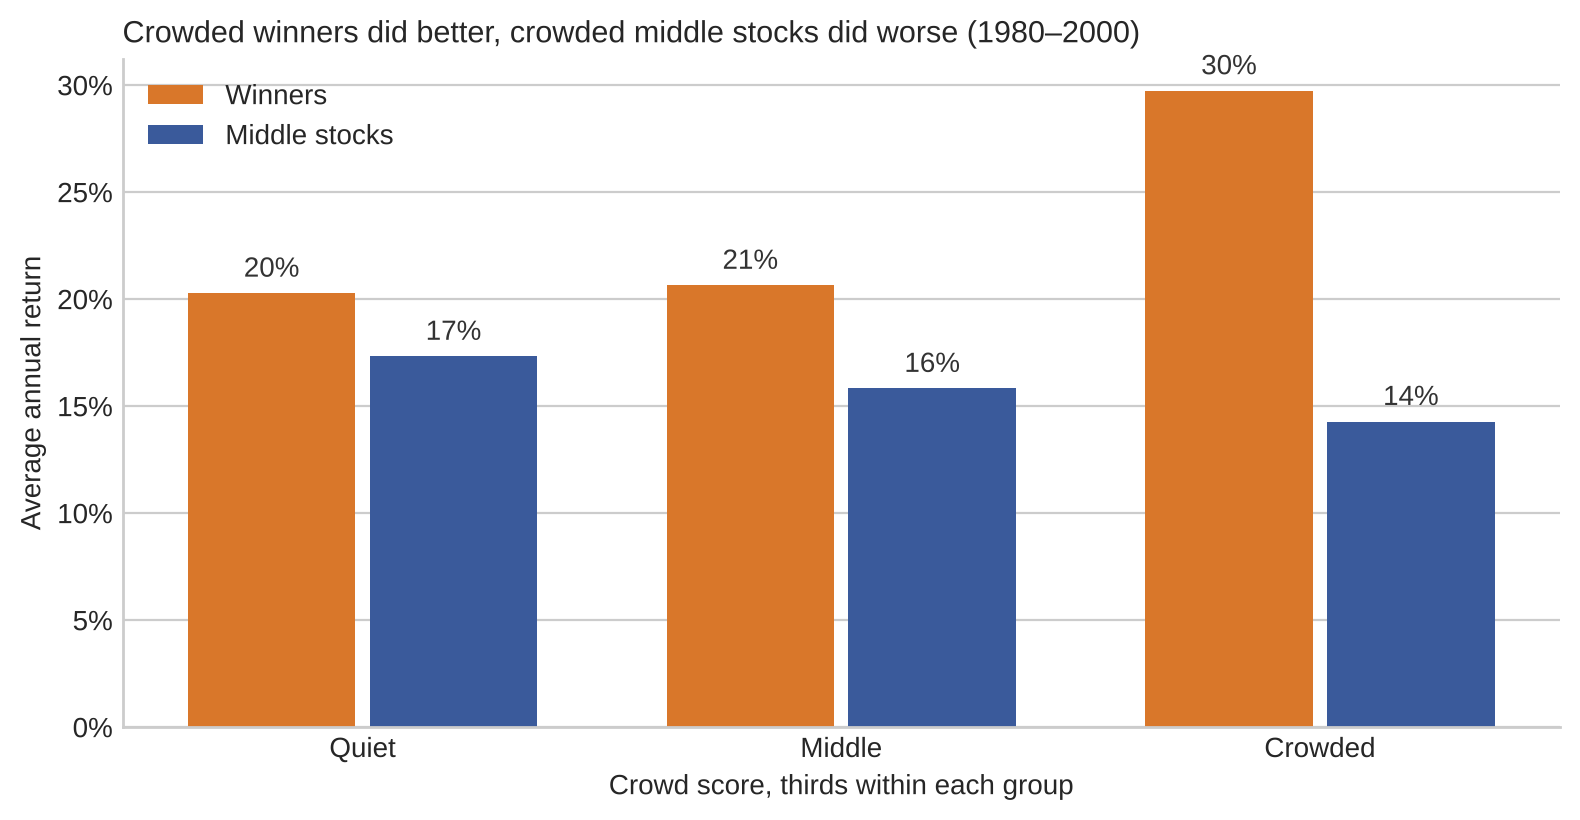

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(3); wbar = 0.38
colors = {'Winners': '#D9772A', 'Middle stocks': '#3A5A9B'}
for i, col in enumerate(['Winners', 'Middle stocks']):
    bars = ax.bar(x + (i - 0.5)*wbar, tab[col]*100, wbar - 0.03, color=colors[col], label=col)
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.5, f"{b.get_height():.0f}%",
                ha='center', va='bottom', fontsize=10, color='#333')
ax.set_xticks(x, ['Quiet', 'Middle', 'Crowded'])
ax.set_ylabel('Average annual return')
ax.set_xlabel('Crowd score, thirds within each group')
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_title('Crowded winners did better, crowded middle stocks did worse (1980–2000)', loc='left', fontsize=11)
ax.legend(frameon=False, loc='upper left')
ax.grid(axis='x', visible=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('crowd_thirds.png', dpi=200); plt.show()

## Step 4 — Each clue on its own

Same test, one clue at a time. Negative = crowded did *better* (against our idea).

In [7]:
rows = []
for c in CROWD:
    sw = (lambda p: p['Quiet'] - p['Crowded'])(thirds(c, 'Winners'))
    sm_ = (lambda p: p['Quiet'] - p['Crowded'])(thirds(c, 'Middle'))
    rw, rg = report(sw), report((sw - sm_).dropna())
    rows.append(pd.Series({'Winners: quiet − crowded': rw['Return'], 'FF6 t (winners)': rw['FF6 t'],
                           'Winners minus middle': rg['Return'], 't (gap)': rg['t']}, name=c))
pd.DataFrame(rows).round(3)

,Winners: quiet − crowded,FF6 t (winners),Winners minus middle,t (gap)
MAX,-0.065,-2.816,-0.095,-2.510
VOL,-0.055,-2.472,-0.103,-2.585
TURN,-0.037,-1.571,-0.028,-0.758
ILLIQ,-0.056,-3.133,-0.093,-3.044
RET1M,0.058,1.276,0.041,1.131


## Step 5 — The trade: drop the 30% most crowded winners

Short leg unchanged. Costs: 25 bps each time we buy or sell, on the turnover of both legs.

In [8]:
COST = 0.0025
W = d[d.grp == 'Winners'].dropna(subset=['CROWD'])
W = W.assign(rank_in_winners=W.groupby('date').CROWD.rank(pct=True))
long_filt, to_long_filt = vw_portfolio(W[W.rank_in_winners <= 0.70])
ls_filt = long_filt - short

out = []
for name, r, to in [('Plain', ls_plain, to_long_plain + to_short),
                    ('Crowd-filtered', ls_filt, to_long_filt + to_short)]:
    r = r.dropna()
    net = r - 2 * to.reindex(r.index).fillna(0) * COST     # buying + selling
    s = report(r, name)
    s['Turnover/month'] = to.mean()
    s['Net return'] = net.mean()*12
    s['Net FF6 alpha'] = report(net)['FF6 alpha']
    out.append(s)
pd.DataFrame(out)[['Return', 'Sharpe', 'FF6 alpha', 'FF6 t', 'Turnover/month', 'Net return', 'Net FF6 alpha']].round(3)

,Return,Sharpe,FF6 alpha,FF6 t,Turnover/month,Net return,Net FF6 alpha
Plain,0.087,0.641,-0.031,-1.148,0.713,0.044,-0.073
Crowd-filtered,0.077,0.568,-0.045,-1.680,0.753,0.032,-0.090


## Step 6 — Is it just the dot-com bubble?

In [9]:
rows = []
for name, a, b in [('1980–1989', '1980', '1989'), ('1990–1997', '1990', '1997'),
                   ('1998–2000', '1998', '2000'), ('All, without 1998–2000', '1980', '1997')]:
    rw, rg = report(spread_w.loc[a:b]), report(gap.loc[a:b])
    rows.append(pd.Series({'Winners: quiet − crowded': rw['Return'], 't': rw['t'],
                           'Winners minus middle': rg['Return'], 't (gap)': rg['t']}, name=name))
pd.DataFrame(rows).round(3)

,Winners: quiet − crowded,t,Winners minus middle,t (gap)
1980–1989,0.039,0.737,-0.047,-0.957
1990–1997,-0.114,-1.576,-0.145,-2.666
1998–2000,-0.483,-1.447,-0.330,-1.729
"All, without 1998–2000",-0.030,-0.678,-0.091,-2.493


## What we found

1. **Our idea was wrong in this data.** Crowded winners did *better* than quiet winners, not worse.
2. **But crowding does interact with momentum.** Among middle stocks, crowded ones did worse (the usual lottery effect).
   Among winners it flips. So the gap between the two groups is real and statistically strong, just in the opposite direction to our prediction.
3. **Dropping crowded winners hurt the strategy**, before and after costs, and it didn't lower turnover.
4. **The late-1990s tech run drives a lot of it.** In the 1980s there's no effect among winners. Without 1998–2000, crowded winners no longer clearly beat quiet ones (−3%/yr, t −0.7), but the winners-vs-middle difference is still there (t −2.5).

**One-line takeaway:** in 1980–2000, crowds didn't break momentum, they fed it. Skipping crowded winners left money on the table.

**What we'd test next:** longer holding periods (do crowded winners reverse after 3–12 months instead of 1?), and 2001–2024 data, which covers the dot-com crash and WallStreetBets.